# **Άσκηση 4 - Naive Bayes**

**Ακριτίδου Ελένη**


---



In [1]:
#Ερώτημα1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv('train.csv')
print(df.shape)
df.head()

# Χωρισμός σε train/test (90-10%) με stratify
train, test = train_test_split(df, test_size=0.10, stratify=df['target'], random_state=0)
print('Train:', train.shape, ' Test:', test.shape)

(7613, 5)
Train: (6851, 5)  Test: (762, 5)


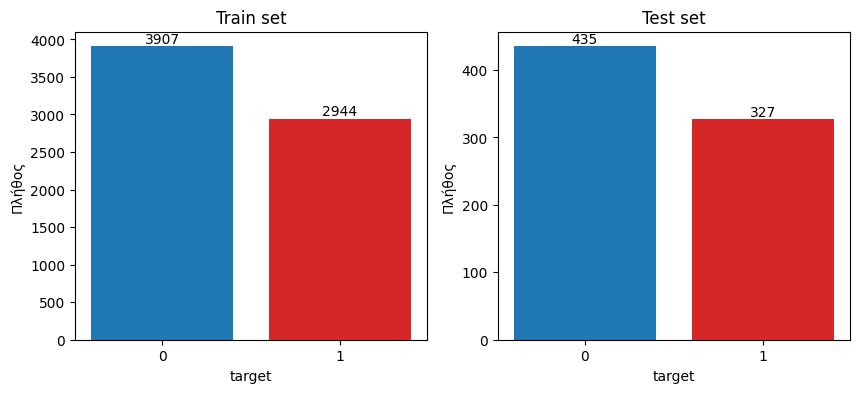

Train %:
 target
0    57.0
1    43.0
Name: proportion, dtype: float64
Test %:
 target
0    57.1
1    42.9
Name: proportion, dtype: float64


In [2]:
# Bar-plot με το πλήθος των target σε train και test
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, name in zip(axes, [train, test], ['Train', 'Test']):
    counts = data['target'].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color=['tab:blue', 'tab:red'])
    ax.set_title(f'{name} set')
    ax.set_xlabel('target')
    ax.set_ylabel('Πλήθος')
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha='center', va='bottom')
plt.show()

print('Train %:\n', (train['target'].value_counts(normalize=True) * 100).round(1))
print('Test %:\n', (test['target'].value_counts(normalize=True) * 100).round(1))

**Παρατήρηση:**

Το σύνολο δεδομένων δεν είναι απόλυτα ισορροπημένο, αλλά παρουσιάζει μια σχετική ισορροπία (περίπου 57% target=0 και 43% target=1). Υπάρχει μικρή υπεροχή της κλάσης 0, αλλά όχι έντονη ανισορροπία.
Χάρη στο stratify, η αναλογία είναι ίδια σε train και test, άρα το test set αντιπροσωπεύει σωστά το train. Το accuracy επομένως είναι μια λογική μετρική.

In [3]:
#Ερώτημα2α

train = train.drop(columns=['id', 'location'])
test = test.drop(columns=['id', 'location'])
train.head()

,keyword,text,target
6669,threat,Meek Mill responds to DrakeÛªs OVO Fest set w...,1
3940,flood,survived the plague\nfloated the flood\njust p...,0
7217,weapons,#Kick Hendrixonfire @'=BLACKCATS= | BIG NOOB ...,0
2234,deluge,Vince McMahon once again a billionaire: I reme...,0
4233,hazardous,Is it possible to sneak into a hospital so I c...,0


In [4]:
#Ερώτημα2β

print('Ελλιπείς τιμές (train):\n', train.isnull().sum())
train = train.fillna('null')
test = test.fillna('null')
print('\nΜετά τη συμπλήρωση:', train.isnull().sum().sum())

Ελλιπείς τιμές (train):
 keyword    54
text        0
target      0
dtype: int64

Μετά τη συμπλήρωση: 0


In [5]:
#Ερώτημα2γ

train['inputs'] = train['keyword'] + ' ' + train['text']
test['inputs'] = test['keyword'] + ' ' + test['text']
train[['inputs', 'target']].head()

,inputs,target
6669,threat Meek Mill responds to DrakeÛªs OVO Fes...,1
3940,flood survived the plague\nfloated the flood\n...,0
7217,weapons #Kick Hendrixonfire @'=BLACKCATS= | B...,0
2234,deluge Vince McMahon once again a billionaire:...,0
4233,hazardous Is it possible to sneak into a hospi...,0


In [6]:
#Ερώτημα3

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Λεξικό με τις πιο συνηθισμένες συντμήσεις
contractions = {"won't": "will not", "can't": "cannot", "n't": " not", "'re": " are",
                "'s": " is", "'d": " would", "'ll": " will", "'t": " not",
                "'ve": " have", "'m": " am"}

def clean_text(text):
    text = re.sub(r'(\\u[0-9A-Fa-f]+)', '', text)
    text = re.sub(r'[^\x00-\x7f]', '', text)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    text = text.lower()
    for k, v in contractions.items():
        text = text.replace(k, v)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    words = text.split()
    words = [w for w in words if w not in stop_words]
    words = [lemmatizer.lemmatize(w) for w in words]
    return ' '.join(words)

train['inputs'] = train['inputs'].apply(clean_text)
test['inputs'] = test['inputs'].apply(clean_text)
train[['inputs', 'target']].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


,inputs,target
6669,threat meek mill responds drake ovo fest set w...,1
3940,flood survived plague floated flood peeked hea...,0
7217,weapon kick hendrixonfire blackcats big noob c...,0
2234,deluge vince mcmahon billionaire remember read...,0
4233,hazardous possible sneak hospital stab hazardo...,0


**Παρατήρηση:**


*  *Αφαίρεση unicode και θορύβου* - Διαγράφει μη-ASCII χαρακτήρες emoji και ειδικά σύμβολα.	Δεν έχουν πληροφορία για το tf-idf και διογκώνουν άσκοπα το λεξιλόγιο.
*  *Αφαίρεση URLs* - Διαγράφει τους συνδέσμους (http, https, www).	Κάθε σύνδεσμος (π.χ. t.co/xyz) είναι μοναδικός και δεν γενικεύεται σε άλλα tweets.
* *Αφαίρεση mentions (@user)* -	Διαγράφει τα ονόματα χρηστών.	Είναι τυχαία και δεν σχετίζονται με το αν υπάρχει καταστροφή.
* *Αφαίρεση του συμβόλου #*	- Κρατά τη λέξη και διαγράφει μόνο το #.	Η λέξη του hashtag (π.χ. #flood) είναι πολύτιμη πληροφορία.
* *Επέκταση συντμήσεων* -	Μετατρέπει π.χ. “don’t” σε “do not”.	Ομογενοποιεί τις λέξεις, ώστε να μη μετρούν ως διαφορετικές.
* *Αφαίρεση αριθμών* - Διαγράφει τα ψηφία.	Σπάνια βοηθούν στη διάκριση των κλάσεων και αυξάνουν το λεξιλόγιο.
* *Αφαίρεση σημείων στίξης* -	Διαγράφει σύμβολα όπως ! ? . ,.	Μειώνει τον θόρυβο και το "κολλημένο" κείμενο, π.χ. “fire!” και “fire”.
* *Μετατροπή σε πεζά*	- Όλα τα γράμματα γίνονται πεζά.	Οι λέξεις “Fire” και “fire” μετρούν ως μία.
* *Αφαίρεση stopwords* - Διαγράφει συχνές λέξεις όπως the, is, at.	Εμφανίζονται παντού και δεν ξεχωρίζουν τις κλάσεις.
* *Lemmatization* -	Φέρνει κάθε λέξη στη βασική της μορφή (floods → flood).	Ενώνει τις παραλλαγές της ίδιας λέξης και μειώνει περαιτέρω το λεξιλόγιο.

In [7]:
#Ερώτημα4

X_train_text = train['inputs'].to_numpy()
y_train = train['target'].to_numpy()
X_test_text = test['inputs'].to_numpy()
y_test = test['target'].to_numpy()
print(X_train_text.shape, y_train.shape, X_test_text.shape, y_test.shape)

(6851,) (6851,) (762,) (762,)


In [8]:
#Ερώτημα5

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(X_train_text).toarray()
X_test = vectorizer.transform(X_test_text).toarray()
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (6851, 5000)  Test: (762, 5000)


In [9]:
#Ερώτημα6

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

model = GaussianNB()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)
print('Accuracy train:', round(accuracy_score(y_train, y_pred_train), 3))
print('Accuracy test :', round(accuracy_score(y_test, y_pred_test), 3))
print()
print(classification_report(y_test, y_pred_test))

Accuracy train: 0.763
Accuracy test : 0.627

              precision    recall  f1-score   support

           0       0.82      0.44      0.58       435
           1       0.54      0.87      0.67       327

    accuracy                           0.63       762
   macro avg       0.68      0.66      0.62       762
weighted avg       0.70      0.63      0.62       762

